# 05 · What is it worth, what could change the answer, and how Stories can prove it

**Everything in this notebook is an estimate.** It combines the measured models (notebooks 01-03) with the explicit
assumptions in `config/assumptions.json`. Stories has never logged a suggestion, so acceptance cannot be measured from
history; we show how the answer moves across a range of acceptance rates, then design the test that measures it.

**Method.** The engine is trained on January-May and replayed on every June order (6,906 orders it never saw). Each
policy is scored with the same acceptance model, so the comparison is fair even though the level is assumed. The
June result per order is scaled to a year using the six-month average volume (68,300 orders a year; June alone is
busier, so this is conservative).

**What we find**
- At base assumptions Stories Pair adds about **$17k of gross profit a year**, beats "suggest the best-seller" by
  about 15%, and beats a classic 10%-off combo by about 37%, which also hands out roughly $3.9k a year in discounts,
  for little extra uptake (about a third of it goes to customers who would have bought anyway).
- Varying every assumption at once (Monte Carlo) gives **P10 about $12k, median about $18k, P90 about $27k a year**,
  and no draw loses money. The biggest driver by far is the acceptance rate, which is what the pilot measures first.
- Discounting the add-on starts to pay only if 10% off raises acceptance by about a quarter or more. Stories' own
  data shows no such effect, so the engine leads with full-price pairings.
- A two-step pilot (2 weeks of acceptance logging, then a 6-week odd/even receipt A/B test across all three branches)
  is enough to replace every assumption here with a measured number.
- **Costs are small next to the gain:** staff time is a few hundred dollars a year at stated wage assumptions, and a
  POS integration pays back within months. The roll-out decision flips only if acceptance turns out very low
  (section 7 gives the thresholds).

In [1]:
# Setup: works in Google Colab, local Jupyter, and from the repo root
import os, sys, subprocess
REPO_URL = "https://github.com/mouhammed-soumaille/EECE-490-Hackathon.git"
if "google.colab" in sys.modules:
    if not os.path.exists("/content/EECE-490-Hackathon"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/EECE-490-Hackathon"], check=True)
    os.chdir("/content/EECE-490-Hackathon")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.join(os.getcwd(), "src"))

import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dataclasses import replace
from storiespair import data, models, engine as E, simulate as S, viz
viz.style()
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

lines = data.load_lines()
orders = data.build_orders(lines)
added = data.other_side_first_item(lines, orders)
ue = data.unit_economics(lines)
cfg = E.load_config()
pm = models.PairModels.fit(orders, lines, added, months=(1, 2, 3, 4, 5))
engine = E.PairEngine(pm, ue, cfg["compatibility"], E.Assumptions.from_config(cfg), E.Guardrails.from_config(cfg))
base = E.Assumptions.from_config(cfg)

annual_orders = len(orders) * 365 / orders.day.nunique()
june = orders[orders.month == 6]
replay = S.Replay(engine, june, annual_orders)
print(f"Replaying {len(june):,} June orders; scaling to {annual_orders:,.0f} orders a year.")
print("Base assumptions:", base)

Replaying 6,906 June orders; scaling to 68,336 orders a year.
Base assumptions: Assumptions(base_acceptance=0.06, discount_lift_per_10pct=0.1, switch_rate=0.1, offer_rate=0.8)


## 1. Policy comparison at base assumptions

In [2]:
comp = replay.compare(base)
show = comp[["policy", "annual_incremental_gp", "annual_discount_given", "annual_extra_items", "gain_per_offer"]].copy()
show.columns = ["policy", "incremental gross profit / yr", "discount handed out / yr", "extra items sold / yr", "gain per suggestion"]
show.round(2)

,policy,incremental gross profit / yr,discount handed out / yr,extra items sold / yr,gain per suggestion
0,Suggest the best-seller (full price),14607.90,0.00,5164.02,0.27
1,Suggest the highest-profit item (full price),11235.88,0.00,1819.43,0.21
2,Classic combo: best-seller at 10% off,12248.80,3858.25,5680.42,0.22
3,"Stories Pair, no discounts",16811.01,0.00,4618.00,0.31
4,Stories Pair (item + discount optimised),16811.01,0.00,4618.00,0.31


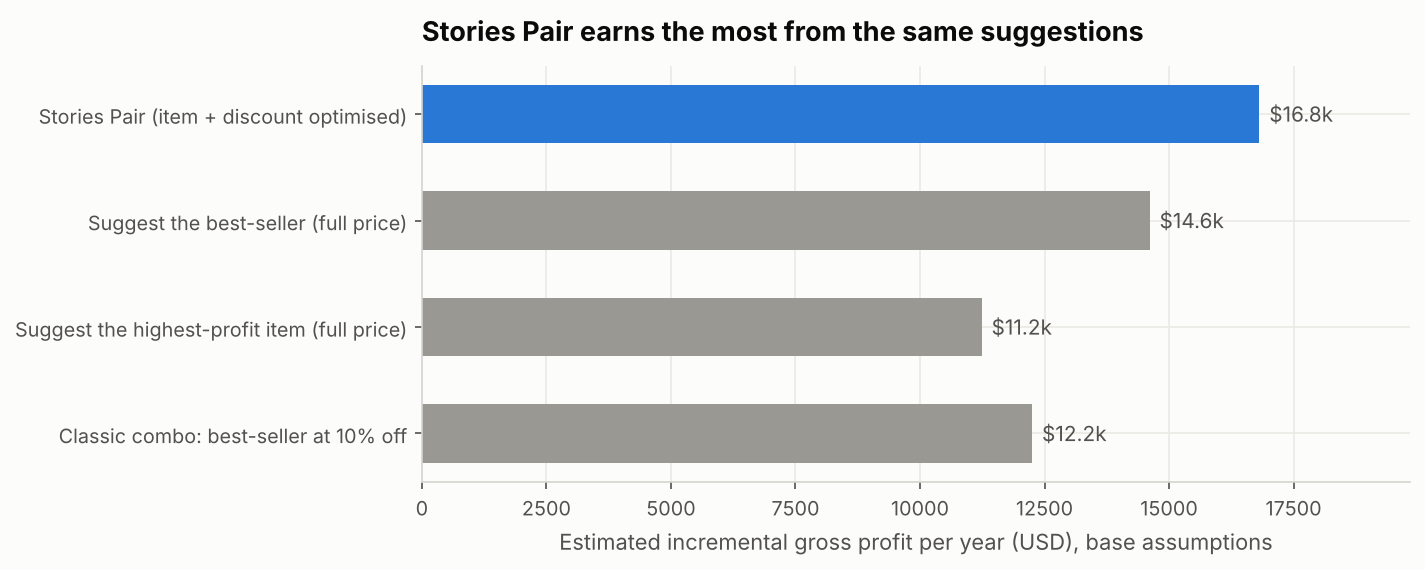

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
c = comp.set_index("policy")
order_ = [S.POLICIES[k] for k in ["fixed_combo_10", "highest_margin", "most_popular", "stories_pair"]]
vals = c.loc[order_, "annual_incremental_gp"]
colors = [viz.GREY, viz.GREY, viz.GREY, viz.BLUE]
ax.barh(range(len(vals)), vals.values, color=colors, height=0.55)
ax.set_yticks(range(len(vals)), vals.index)
for i, v in enumerate(vals.values):
    ax.text(v + 200, i, f"${v/1000:,.1f}k", va="center", fontsize=10, color=viz.INK_2)
ax.set_xlabel("Estimated incremental gross profit per year (USD), base assumptions")
ax.set_title("Stories Pair earns the most from the same suggestions")
ax.set_xlim(0, vals.max() * 1.18)
viz.savefig(fig, "05_policy_comparison")
plt.show()

Why the classic combo loses: about 1 in 4 drink-first orders and 1 in 3 food-first orders would pair anyway; a
blanket 10% discount is also paid on those sales, and on every new one, while discounts buy little extra uptake (about a third of the combo's discount goes to people who would have bought anyway). Why "highest margin" loses: it pushes items people rarely choose, so
few accept. Stories Pair balances the two.

## 2. How much depends on the acceptance rate?

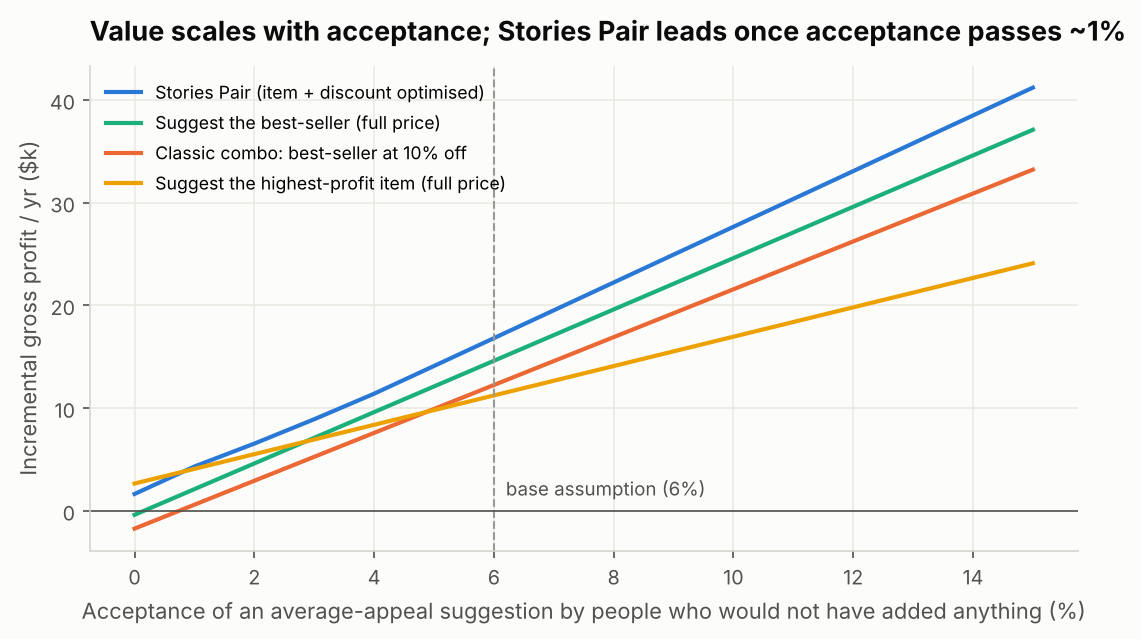

In [4]:
curve = replay.acceptance_curve(base, grid=np.linspace(0, 0.15, 16))
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for key, col in [("stories_pair", viz.BLUE), ("most_popular", viz.AQUA), ("fixed_combo_10", viz.ORANGE), ("highest_margin", viz.YELLOW)]:
    d = curve[curve.key == key]
    ax.plot(d.base_acceptance * 100, d.annual_incremental_gp / 1000, color=col, label=S.POLICIES[key])
ax.axvline(base.base_acceptance * 100, color=viz.GREY, ls="--", lw=1)
ax.text(base.base_acceptance * 100 + 0.2, 1.5, "base assumption (6%)", color=viz.INK_2, fontsize=9)
ax.axhline(0, color=viz.INK_2, lw=0.8)
ax.set_xlabel("Acceptance of an average-appeal suggestion by people who would not have added anything (%)")
ax.set_ylabel("Incremental gross profit / yr ($k)")
ax.set_title("Value scales with acceptance; Stories Pair leads once acceptance passes ~1%")
ax.legend(loc="upper left", fontsize=8.5)
viz.savefig(fig, "05_acceptance_curve")
plt.show()

In [5]:
slope = np.polyfit(curve[curve.key == "stories_pair"].base_acceptance, curve[curve.key == "stories_pair"].annual_incremental_gp, 1)[0]
be_combo = replay.break_even_acceptance("fixed_combo_10", base)
print(f"Each extra percentage point of acceptance is worth about ${slope/100:,.0f} a year with Stories Pair.")
print(f"The classic 10% combo needs at least {be_combo:.1%} acceptance just to cover the discounts it gives away.")
print("Below ~1% acceptance Stories Pair mostly stays silent: it does not ask staff to make a suggestion worth under $0.05.")

Each extra percentage point of acceptance is worth about $2,653 a year with Stories Pair.
The classic 10% combo needs at least 0.7% acceptance just to cover the discounts it gives away.
Below ~1% acceptance Stories Pair mostly stays silent: it does not ask staff to make a suggestion worth under $0.05.


## 3. When does a discount start to pay?

In [6]:
rows = []
for lift in [0.0, 0.1, 0.2, 0.25, 0.3, 0.4, 0.5, 0.75, 1.0]:
    a = replace(base, discount_lift_per_10pct=lift)
    with_d = replay.run("stories_pair", a)
    no_d = replay.run("stories_pair_nodisc", a)
    combo = replay.run("fixed_combo_10", a)
    rows.append({"acceptance lift per 10% off": lift, "Stories Pair (may discount)": with_d["annual_incremental_gp"],
                 "Stories Pair (no discounts)": no_d["annual_incremental_gp"],
                 "classic 10% combo": combo["annual_incremental_gp"],
                 "discount handed out by Stories Pair": with_d["annual_discount_given"]})
disc = pd.DataFrame(rows)
disc["value of allowing discounts"] = disc["Stories Pair (may discount)"] - disc["Stories Pair (no discounts)"]
disc.style.format({c: "${:,.0f}" for c in disc.columns if c != "acceptance lift per 10% off"} | {"acceptance lift per 10% off": "+{:.0%}"})

,acceptance lift per 10% off,Stories Pair (may discount),Stories Pair (no discounts),classic 10% combo,discount handed out by Stories Pair,value of allowing discounts
0,+0%,"$16,811","$16,811","$10,978",$0,$0
1,+10%,"$16,811","$16,811","$12,249",$0,$0
2,+20%,"$16,811","$16,811","$13,519",$45,$0
3,+25%,"$16,857","$16,811","$14,155","$1,055",$46
4,+30%,"$17,107","$16,811","$14,790","$2,074",$296
5,+40%,"$18,242","$16,811","$16,061","$5,462","$1,431"
6,+50%,"$19,850","$16,811","$17,331","$7,950","$3,039"
7,+75%,"$24,302","$16,811","$20,508","$9,892","$7,491"
8,+100%,"$28,883","$16,811","$23,684","$11,540","$12,072"


Up to a lift of about +20-25% per 10% off, the engine keeps every suggestion at full price, because discounts would
lose money. Above that, it starts discounting selectively. The classic combo only catches up with the full-price
engine when discounts lift acceptance by roughly +40-50%, far beyond anything visible in Stories' data (notebook 01:
a discounted first drink was not associated with any more pairing).

## 4. Uncertainty: every assumption at once

In [7]:
mc = replay.monte_carlo(cfg["assumptions"], n=400, seed=7)
q = mc.annual_incremental_gp.quantile([0.1, 0.5, 0.9])
print(f"Annual incremental gross profit, Stories Pair (400 draws, triangular low/base/high):")
print(f"  P10 ${q[0.1]:,.0f}   median ${q[0.5]:,.0f}   P90 ${q[0.9]:,.0f}")
print(f"  share of draws below zero: {(mc.annual_incremental_gp < 0).mean():.1%}")

Annual incremental gross profit, Stories Pair (400 draws, triangular low/base/high):
  P10 $11,835   median $18,497   P90 $26,878
  share of draws below zero: 0.0%


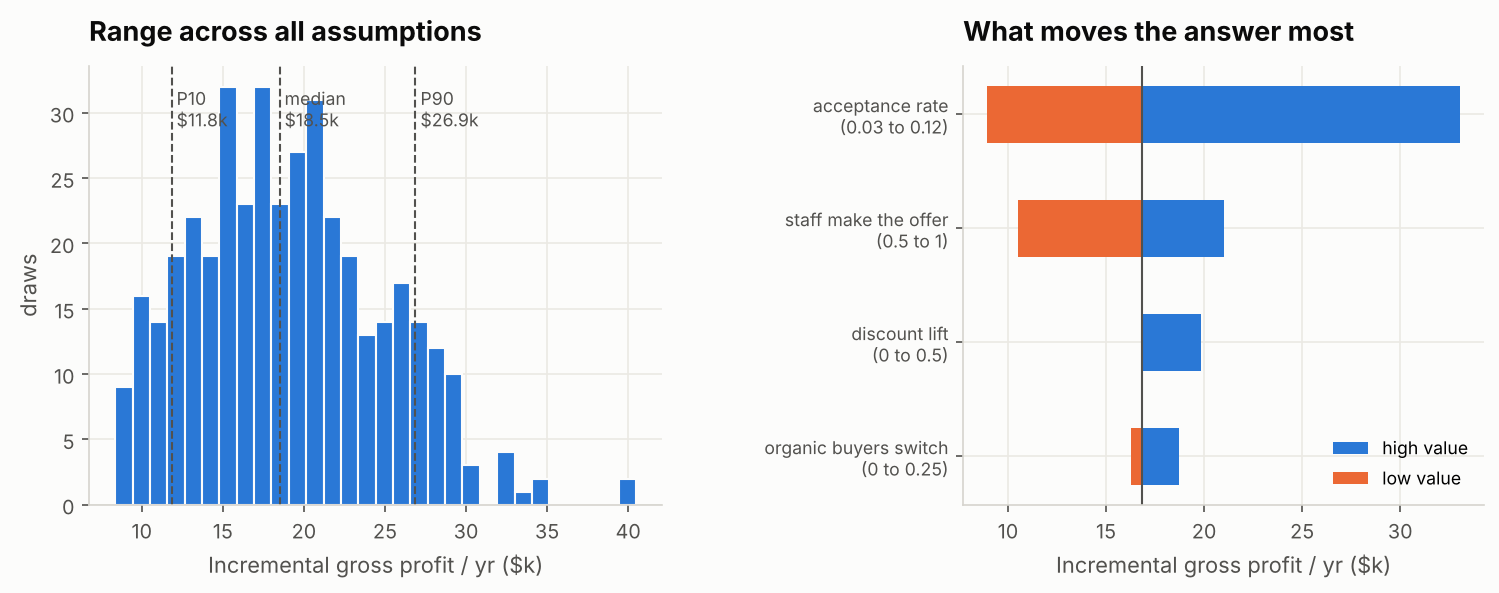

In [8]:
tor = replay.tornado(cfg["assumptions"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.1, 1], "wspace": 0.55})
ax = axes[0]
ax.hist(mc.annual_incremental_gp / 1000, bins=30, color=viz.BLUE, edgecolor=viz.SURFACE)
for qq, lab in [(0.1, "P10"), (0.5, "median"), (0.9, "P90")]:
    ax.axvline(q[qq] / 1000, color=viz.INK_2, ls="--", lw=1)
    ax.text(q[qq] / 1000, ax.get_ylim()[1] * 0.95, f" {lab}\n ${q[qq]/1000:.1f}k", fontsize=8.5, color=viz.INK_2, va="top")
ax.set_xlabel("Incremental gross profit / yr ($k)"); ax.set_ylabel("draws")
ax.set_title("Range across all assumptions")
ax = axes[1]
names = {"base_acceptance": "acceptance rate", "offer_rate": "staff make the offer",
         "switch_rate": "organic buyers switch", "discount_lift_per_10pct": "discount lift"}
t = tor.iloc[::-1]
y = np.arange(len(t))
basev = t.base.iloc[0] / 1000
ax.barh(y, t.annual_gp_at_high / 1000 - basev, left=basev, color=viz.BLUE, height=0.5, label="high value")
ax.barh(y, t.annual_gp_at_low / 1000 - basev, left=basev, color=viz.ORANGE, height=0.5, label="low value")
ax.axvline(basev, color=viz.INK_2, lw=1)
ax.set_yticks(y, [f"{names[k]}\n({lo:g} to {hi:g})" for k, lo, hi in zip(t.assumption, t.low_value, t.high_value)], fontsize=8.5)
ax.set_xlabel("Incremental gross profit / yr ($k)")
ax.set_title("What moves the answer most")
ax.legend(loc="lower right", fontsize=8.5)
viz.savefig(fig, "05_uncertainty")
plt.show()

In [9]:
tor.style.format({"low_value": "{:g}", "high_value": "{:g}", "annual_gp_at_low": "${:,.0f}", "annual_gp_at_high": "${:,.0f}", "base": "${:,.0f}", "swing": "${:,.0f}"})

,assumption,low_value,high_value,annual_gp_at_low,annual_gp_at_high,base,swing
0,base_acceptance,0.03,0.12,"$8,919","$33,069","$16,811","$24,150"
1,offer_rate,0.5,1,"$10,507","$21,014","$16,811","$10,507"
2,discount_lift_per_10pct,0,0.5,"$16,811","$19,850","$16,811","$3,039"
3,switch_rate,0,0.25,"$16,258","$18,715","$16,811","$2,458"


## 5. Measured vs estimated

| Statement | Status | Where |
|---|---|---|
| 72% of orders are single-sided (40.9% drink-only, 30.9% food-only) | **measured** | 00 |
| Pairing rate varies with the first item's category, not with branch/hour/order type | **measured** (tested, held-out) | 01, 03 |
| Which category is added varies with the first item's category | **measured** (tested, held-out) | 01, 02, 03 |
| No product-level pairing beyond the category | **measured** (tested, corrected for multiple tests) | 02 |
| Garden unit costs are 1.43x Harbour on all 45 products | **measured** | 01 |
| A discounted first drink was not associated with more pairing | **measured** (association, not a randomized test) | 01 |
| The first line of an order is the item rung first | **assumed** (supported by notebook 02) | 00, 02 |
| 6% base acceptance, 10% switching, 80% staff compliance, +10% acceptance per 10% off | **assumed** | config |
| ~$17k/yr incremental gross profit, P10-P90 range above | **estimated** | 05 |

Gross profit is not net profit: these figures exclude staff time, waste and any POS change cost.

## 6. The pilot Stories can run next month

**Step 1 · Acceptance logging (2 weeks, all branches).** Staff make the playbook suggestion on every eligible order
and tap *accepted / declined*. This measures the single biggest unknown (acceptance) directly. Estimating a ~6%
acceptance rate to within about ±1 point needs roughly 2,200 suggestions: about two weeks at current volume
(~187 orders a day, 80% of them shown a suggestion).

**Step 2 · Odd/even receipt A/B test (6 weeks, all branches).** Orders with an even Transaction ID get the
suggestion, odd ones do not. Six weeks can detect about $0.18 of extra gross profit per order (table below); the
base case predicts $0.25. No customer data needed, nothing for staff to remember, and the POS already numbers
receipts. Primary metric: gross profit per order. Secondary: pairing rate, acceptance, discount spend, complaints.

In [10]:
pilot, sd_gp, daily = S.pilot_table(orders, effects_usd=(0.10, 0.15, 0.20, 0.25, 0.30))
print(f"Order-level gross profit: SD ${sd_gp:.2f}; orders per day: " + ", ".join(f"{b} {v:.0f}" for b, v in daily.items()))
pilot

Order-level gross profit: SD $2.79; orders per day: Garden 62, Harbour 90, Uptown 35


,detectable_gain_per_order_usd,orders_per_arm,all_branches_days,Garden_only_days,Harbour_only_days,Uptown_only_days
0,0.10,12190,131,396,271,691
1,0.15,5418,58,176,121,307
2,0.20,3048,33,99,68,173
3,0.25,1951,21,64,44,111
4,0.30,1355,15,44,31,77


In [11]:
# Expected effect per order in the A/B test = gain per suggestion x share of orders that get one
eff = comp.set_index("key").loc["stories_pair"]
per_order = eff.annual_incremental_gp / annual_orders
n_arm = S.power_per_arm(sd_gp, per_order)
print(f"Base-case effect: ${per_order:.2f} gross profit per order across all orders.")
print(f"Orders per arm for 80% power at 5% significance: {n_arm:,}  ->  about {2*n_arm/daily.sum():.0f} days at all three branches.")
# pairing-rate metric is more sensitive
p0 = orders.paired.mean()
from scipy import stats
z = stats.norm.ppf(0.975) + stats.norm.ppf(0.8)
for uplift in [0.02, 0.03]:
    p1 = p0 + uplift
    n = int(np.ceil(z**2 * (p0*(1-p0) + p1*(1-p1)) / uplift**2))
    print(f"To detect pairing rate {p0:.1%} -> {p1:.1%}: {n:,} orders per arm (~{2*n/daily.sum():.0f} days)")

Base-case effect: $0.25 gross profit per order across all orders.
Orders per arm for 80% power at 5% significance: 2,015  ->  about 22 days at all three branches.
To detect pairing rate 28.2% -> 30.2%: 8,113 orders per arm (~87 days)
To detect pairing rate 28.2% -> 31.2%: 3,640 orders per arm (~39 days)


**Decision rules, agreed before the test starts**
- Roll out to all orders if gross profit per order is higher in the suggestion arm at the 5% level.
- If acceptance is below about 2% after Step 1, stop: the engine cannot earn its keep (notebook 05, section 2).
- Test a discounted variant only if Step 2 succeeds and only on one branch, since the data gives no prior support.
- Re-fit the playbook monthly with the logged accept/decline data; the acceptance term then becomes measured.

## 7. Costs, net value and what would change the decision

Everything above is **gross** profit. The engine also has costs. Two are quantifiable with stated assumptions
(`config/assumptions.json`); the rest are listed as tradeoffs.

- **Staff time.** Each suggestion adds a few seconds at the till.
- **Integration.** A one-off cost to add the suggestion and an accept/decline button to the POS. Stories' POS vendor
  and price are not in the data, so we show the payback for a range of costs instead of guessing one.

In [12]:
A = cfg["assumptions"]
def staff_cost(offers, secs, wage):
    return offers * secs / 3600 * wage

sp = comp.set_index("key").loc["stories_pair"]
rows = []
for label, secs, wage in [("low", A["staff_seconds_per_suggestion"]["low"], A["staff_cost_per_hour_usd"]["low"]),
                          ("base", A["staff_seconds_per_suggestion"]["base"], A["staff_cost_per_hour_usd"]["base"]),
                          ("high", A["staff_seconds_per_suggestion"]["high"], A["staff_cost_per_hour_usd"]["high"])]:
    c = staff_cost(sp.annual_offers, secs, wage)
    rows.append({"staff-cost case": label, "seconds per suggestion": secs, "cost per staff hour": wage,
                 "staff hours / yr": sp.annual_offers * secs / 3600, "staff cost / yr": c,
                 "net gain / yr (base acceptance)": sp.annual_incremental_gp - c})
costs = pd.DataFrame(rows)
costs.style.format({"cost per staff hour": "${:.2f}", "staff hours / yr": "{:,.0f}", "staff cost / yr": "${:,.0f}",
                    "net gain / yr (base acceptance)": "${:,.0f}"})

,staff-cost case,seconds per suggestion,cost per staff hour,staff hours / yr,staff cost / yr,net gain / yr (base acceptance)
0,low,3,$2.50,46,$114,"$16,697"
1,base,5,$4.00,76,$304,"$16,507"
2,high,8,$6.00,121,$729,"$16,082"


In [13]:
base_staff = staff_cost(sp.annual_offers, A["staff_seconds_per_suggestion"]["base"], A["staff_cost_per_hour_usd"]["base"])
net = sp.annual_incremental_gp - base_staff
pay = pd.DataFrame({"one-off integration cost": [1000, 3000, 5000, 10000]})
pay["payback (months)"] = (pay["one-off integration cost"] / (net / 12)).round(1)
print(f"Net gain after base staff time: ${net:,.0f} a year (${net/12:,.0f} a month).")
pay.style.format({"one-off integration cost": "${:,.0f}", "payback (months)": "{:.1f}"})

Net gain after base staff time: $16,507 a year ($1,376 a month).


,one-off integration cost,payback (months)
0,"$1,000",0.7
1,"$3,000",2.2
2,"$5,000",3.6
3,"$10,000",7.3


In [14]:
def acceptance_needed(target_net, policy="stories_pair"):
    """Base acceptance at which yearly gross gain minus base staff cost reaches target_net.

    Conservative: assumes no switching benefit (w = 0), so all value must come from new sales."""
    def f(r):
        res = replay.run(policy, replace(base, base_acceptance=r, switch_rate=0.0))
        return res["annual_incremental_gp"] - staff_cost(res["annual_offers"], A["staff_seconds_per_suggestion"]["base"],
                                                          A["staff_cost_per_hour_usd"]["base"]) - target_net
    lo, hi = 0.0, 0.3
    for _ in range(30):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if f(mid) < 0 else (lo, mid)
    return hi

r_be = acceptance_needed(0)
r_5k = acceptance_needed(5000)

# Garden: what if its unit costs matched Harbour's?
ue_fix = ue.copy()
h_cost = ue[ue.branch == "Harbour"].set_index("product").cost
mask = ue_fix.branch == "Garden"
ue_fix.loc[mask, "cost"] = ue_fix.loc[mask, "product"].map(h_cost).values
ue_fix["unit_gp"] = ue_fix.price - ue_fix.cost
eng_fix = E.PairEngine(pm, ue_fix, cfg["compatibility"], base, engine.g)
pb_now = engine.playbook(); pb_fix = eng_fix.playbook()
g_now = pb_now[pb_now.branch == "Garden"].set_index("first_item").suggest
g_fix = pb_fix[pb_fix.branch == "Garden"].set_index("first_item").suggest
n_change = int((g_now != g_fix).sum())

lift_rows = disc[disc["value of allowing discounts"] > 1]
lift_flip = float(lift_rows["acceptance lift per 10% off"].min()) if len(lift_rows) else float("nan")

flips = pd.DataFrame([
    {"recommendation": "Make suggestions at all",
     "changes if": (f"never on staff time alone: a suggestion costs about ${base_staff / sp.annual_offers:.3f} of staff time and the "
                    f"engine only makes one worth at least ${engine.g.min_expected_gain_usd:.2f}, so it goes quiet before it loses money"),
     "how we will know": "built into the engine"},
    {"recommendation": "Roll out and pay for POS integration",
     "changes if": f"acceptance is below {r_5k:.1%} (needed to clear staff time plus a $5k integration in year one; no switching benefit)",
     "how we will know": "pilot step 1"},
    {"recommendation": "No discounts on add-ons",
     "changes if": f"10% off lifts acceptance by about {lift_flip:.0%} or more (the engine then starts discounting)",
     "how we will know": "one-branch discount test after step 2; v2 learns it automatically"},
    {"recommendation": "Different suggestions at Garden",
     "changes if": f"Garden's unit costs fall to Harbour's level: {n_change} of 45 Garden suggestions would change",
     "how we will know": "Stories' supplier and recipe records (not in the data)"},
    {"recommendation": "Six-week A/B test is long enough",
     "changes if": "the true effect is under ~$0.18 per order; then extend to 8-10 weeks",
     "how we will know": "pilot step 1 acceptance estimate"},
])
flips

,recommendation,changes if,how we will know
0,Make suggestions at all,never on staff time alone: a suggestion costs ...,built into the engine
1,Roll out and pay for POS integration,acceptance is below 2.0% (needed to clear staf...,pilot step 1
2,No discounts on add-ons,10% off lifts acceptance by about 25% or more ...,one-branch discount test after step 2; v2 lear...
3,Different suggestions at Garden,Garden's unit costs fall to Harbour's level: 7...,Stories' supplier and recipe records (not in t...
4,Six-week A/B test is long enough,the true effect is under ~$0.18 per order; the...,pilot step 1 acceptance estimate


**Tradeoffs we cannot price from this data**
- **Customer experience.** A suggestion can annoy. Mitigations built in: at most one suggestion per order, never on a
  complete pair, never repeated after a decline, staff can skip it. The pilot tracks complaints and declines.
- **Stock and waste.** Suggesting the same few items (Butter Croissant, Egg Sandwich, Iced Latte) concentrates
  demand; branches need to stock for it. Waste and stock-outs are not in the data.
- **Cannibalisation inside the basket.** Modelled through the switching term (w); a pilot measures it directly.
- **Staff compliance.** Modelled as the share of orders where the suggestion is made (80% base); it moves the value
  proportionally (notebook 05, section 4).

**Missing information** that would sharpen the answer: suggestion and acceptance logs (none exist yet), POS ring
order, labour cost per hour, waste and stock levels, POS integration cost, customer complaints, and the reason for
Garden's 1.43x unit costs.

In [15]:
viz.savetable(comp, "05_policy_comparison")
viz.savetable(disc, "05_discount_break_even")
viz.savetable(mc, "05_monte_carlo")
viz.savetable(pilot, "05_pilot_power")
viz.savetable(costs, "05_costs")
_ = viz.savetable(flips, "05_decision_flips")